# 42. Trapping Rain Water

## Problem Statement

Given $n$ non-negative integers representing an elevation map where the width of each bar is `1`, compute how much water it can trap after raining.

---

### Examples

#### Example 1

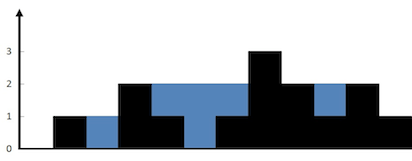


* **Input:** `height = [0,1,0,2,1,0,1,3,2,1,2,1]`
* **Output:** `6`
* **Explanation:** The elevation map is represented by array `[0,1,0,2,1,0,1,3,2,1,2,1]`. In this case, 6 units of rain water are trapped.

#### Example 2
* **Input:** `height = [4,2,0,3,2,5]`
* **Output:** `9`

---

### Constraints
* $n == \text{height.length}$
* $1 \le n \le 2 \times 10^4$
* $0 \le \text{height}[i] \le 10^5$

---

## Optimal Solution (Two Pointers)

### Intuition & Approach
The trapped water at any given position $i$ depends on the maximum height to its left and the maximum height to its right:
$$\text{trapped\_water}[i] = \max(0, \min(\text{left\_max}, \text{right\_max}) - \text{height}[i])$$

Instead of computing `left_max` and `right_max` arrays using $\mathcal{O}(n)$ extra space, we can use a **Two Pointers** approach (`left` starting at `0` and `right` starting at `n - 1`):

1. Maintain `left_max` and `right_max` variables.
2. At each step, compare `height[left]` and `height[right]`:
   - If `height[left] < height[right]`: 
     - Update `left_max = max(left_max, height[left])`.
     - Add `left_max - height[left]` to `total_water`.
     - Advance `left` pointer to the right (`left += 1`).
   - Else:
     - Update `right_max = max(right_max, height[right])`.
     - Add `right_max - height[right]` to `total_water`.
     - Advance `right` pointer to the left (`right -= 1`).

Because the smaller boundary limits the water container depth, we only need to move the pointer on the smaller side.


In [2]:
class Solution:
    def trap(self, height: List[int]) -> int:
        left = 0
        right = len(height)-1
        left_max = 0
        right_max = 0
        water = 0

        while left < right:
            if height[left] < height[right]:
                if height[left] >= left_max:
                    left_max = height[left]
                else:
                    water += left_max - height[left]
                left += 1
            else:
                if height[right] >= right_max:
                    right_max = height[right]
                else:
                    water += right_max - height[right]
                right -= 1
        return water


In [3]:
sol = Solution()
res = sol.trap([0,1,0,2,1,0,1,3,2,1,2,1])
print(res)

6


In [4]:
sol = Solution()
res = sol.trap([4,2,0,3,2,5])
print(res)

9


### Complexity
* **Time Complexity:** $\mathcal{O}(n)$ — Single traversal using two pointers.
* **Space Complexity:** $\mathcal{O}(1)$ — Constant extra memory used.

## Second approach using Prefix/Suffix Max Arrays Approach

In [8]:
class Solution:
    def trapwater(self, height: list[int]) -> int:
        n = len(height)
        if n == 0:
            return 0
            
        left = [0] * n
        right = [0] * n
        
        # Build left max array
        left[0] = height[0]
        for i in range(1, n):
            left[i] = max(left[i - 1], height[i])
            
        # Build right max array
        right[n - 1] = height[n - 1]
        for i in range(n - 2, -1, -1):
            right[i] = max(right[i + 1], height[i])
            
        # Compute total water trapped
        total_water = 0
        for i in range(n):
            total_water += min(left[i], right[i]) - height[i]
            
        return total_water

In [10]:
sol = Solution()
res = sol.trapwater([4,2,0,3,2,5])
print(res)

9


In [11]:
sol = Solution()
res = sol.trapwater([0,1,0,2,1,0,1,3,2,1,2,1])
print(res)

6


### Time Complexity: $\mathcal{O}(n)$
* **Pass 1:** Iterating from left to right to build the `left` prefix max array takes $\mathcal{O}(n)$ operations.
* **Pass 2:** Iterating from right to left to build the `right` suffix max array takes $\mathcal{O}(n)$ operations.
* **Pass 3:** Iterating through the array to compute `min(left[i], right[i]) - a[i]` takes $\mathcal{O}(n)$ operations.
* **Total Time Complexity:** $\mathcal{O}(n) + \mathcal{O}(n) + \mathcal{O}(n) = \mathcal{O}(n)$.

---

### Space Complexity: $\mathcal{O}(n)$
* Creating the `left` array requires $\mathcal{O}(n)$ extra space.
* Creating the `right` array requires $\mathcal{O}(n)$ extra space.
* **Total Space Complexity:** $\mathcal{O}(n)$ auxiliary space to store precomputed max heights.